<a href="https://colab.research.google.com/github/mbryan56/Intro-Machine-Learning-Projects/blob/main/Homework_5_Intro_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=================== PROBLEM 1 TRAINING LOGS ===================

--- Learning Rate: 0.1 ---
Epoch  | Loss      
--------------------
1      | 154.0711  
500    | 2.0907    
1000   | 2.0907    
1500   | 2.0907    
2000   | 2.0907    
2500   | 2.0907    
3000   | 2.0907    
3500   | 2.0907    
4000   | 2.0907    
4500   | 2.0907    
5000   | 2.0907    
Weights: w1=9.1033, w2=0.8019, b=9.7710

--- Learning Rate: 0.01 ---
Epoch  | Loss      
--------------------
1      | 154.0711  
500    | 2.0923    
1000   | 2.0907    
1500   | 2.0907    
2000   | 2.0907    
2500   | 2.0907    
3000   | 2.0907    
3500   | 2.0907    
4000   | 2.0907    
4500   | 2.0907    
5000   | 2.0907    
Weights: w1=9.1034, w2=0.8019, b=9.7710

--- Learning Rate: 0.001 ---
Epoch  | Loss      
--------------------
1      | 154.0711  
500    | 25.7404   
1000   | 8.2874    
1500   | 3.9923    
2000   | 2.7341    
2500   | 2.3202    
3000   | 2.1747    
3500   | 2.1218    
4000   | 2.1023    
4500   | 2.0950    
5000  

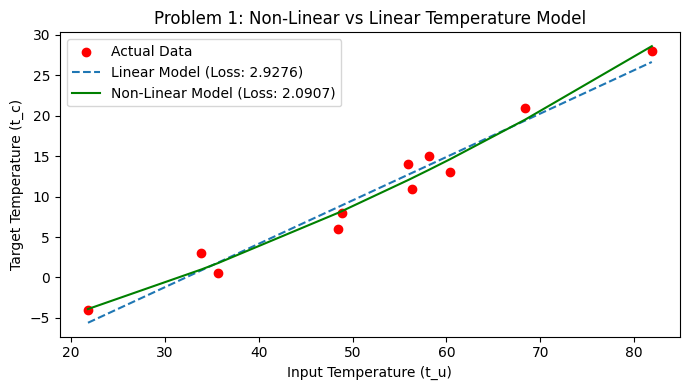

In [ ]:
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 1. Dataset Setup
t_c = [0.5,  14.0, 15.0, 28.0, 11.0,  8.0,  3.0, -4.0,  6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]

t_c = torch.tensor(t_c).unsqueeze(1)
t_u = torch.tensor(t_u).unsqueeze(1)

# Normalization: Z-score standardization for t_u
t_un = (t_u - t_u.mean()) / t_u.std()

def model_nonlinear(t_un, w1, w2, b):
    return w2 * (t_un ** 2) + w1 * t_un + b

def model_linear(t_un, w1, b):
    return w1 * t_un + b

def loss_fn(t_p, t_c):
    return torch.mean((t_p - t_c) ** 2)

def train_p1(epochs, learning_rate, t_un, t_c):
    params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
    optimizer = optim.SGD([params], lr=learning_rate)
    loss_history = []

    for epoch in range(1, epochs + 1):
        if params.grad is not None:
            params.grad.zero_()

        t_p = model_nonlinear(t_un, params[0], params[1], params[2])
        loss = loss_fn(t_p, t_c)
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0 or epoch == 1:
            loss_history.append((epoch, loss.item()))

    return params, loss_history

learning_rates_p1 = [0.1, 0.01, 0.001, 0.0001]
p1_results = {}

print("=================== PROBLEM 1 TRAINING LOGS ===================")
for lr in learning_rates_p1:
    params, losses = train_p1(5000, lr, t_un, t_c)
    p1_results[lr] = (params, losses)
    print(f"\n--- Learning Rate: {lr} ---")
    print(f"{'Epoch':<6} | {'Loss':<10}")
    print("-" * 20)
    for epoch, loss in losses:
        print(f"{epoch:<6d} | {loss:<10.4f}")
    print(f"Weights: w1={params[0].item():.4f}, w2={params[1].item():.4f}, b={params[2].item():.4f}")

# Baseline Linear Model
params_lin = torch.tensor([1.0, 0.0], requires_grad=True)
opt_lin = optim.SGD([params_lin], lr=0.01)
for epoch in range(1, 5001):
    if params_lin.grad is not None:
        params_lin.grad.zero_()
    t_p_lin = model_linear(t_un, params_lin[0], params_lin[1])
    loss_lin = loss_fn(t_p_lin, t_c)
    loss_lin.backward()
    opt_lin.step()

# Visualization
plt.figure(figsize=(7, 4))
best_lr_p1 = 0.01
best_params_p1 = p1_results[best_lr_p1][0]

t_p_non = model_nonlinear(t_un, best_params_p1[0], best_params_p1[1], best_params_p1[2]).detach()
t_p_lin = model_linear(t_un, params_lin[0], params_lin[1]).detach()

sorted_indices = torch.argsort(t_u.squeeze())
plt.scatter(t_u.numpy(), t_c.numpy(), color='red', label='Actual Data')
plt.plot(t_u[sorted_indices].numpy(), t_p_lin[sorted_indices].numpy(),
         label=f'Linear Model (Loss: {loss_lin.item():.4f})', linestyle='--')
plt.plot(t_u[sorted_indices].numpy(), t_p_non[sorted_indices].numpy(),
         label=f'Non-Linear Model (Loss: {p1_results[best_lr_p1][1][-1][1]:.4f})', color='green')
plt.xlabel('Input Temperature (t_u)')
plt.ylabel('Target Temperature (t_c)')
plt.title('Problem 1: Non-Linear vs Linear Temperature Model')
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

=================== PROBLEM 2: 5 INPUT FEATURES ===================

--- LR: 0.1 ---
Epoch  | Train Loss | Val Loss  
--------------------------------
1      | 2.1710     | 2.0946    
500    | 0.4378     | 0.7436    
1000   | 0.4378     | 0.7436    
1500   | 0.4378     | 0.7436    
2000   | 0.4378     | 0.7436    
2500   | 0.4378     | 0.7436    
3000   | 0.4378     | 0.7436    
3500   | 0.4378     | 0.7436    
4000   | 0.4378     | 0.7436    
4500   | 0.4378     | 0.7436    
5000   | 0.4378     | 0.7436    
Params: [0.3873, 0.0643, 0.322, 0.2417, 0.1642] bias: 0.0000

--- LR: 0.01 ---
Epoch  | Train Loss | Val Loss  
--------------------------------
1      | 4.7888     | 4.6710    
500    | 0.4379     | 0.7435    
1000   | 0.4378     | 0.7436    
1500   | 0.4378     | 0.7436    
2000   | 0.4378     | 0.7436    
2500   | 0.4378     | 0.7436    
3000   | 0.43

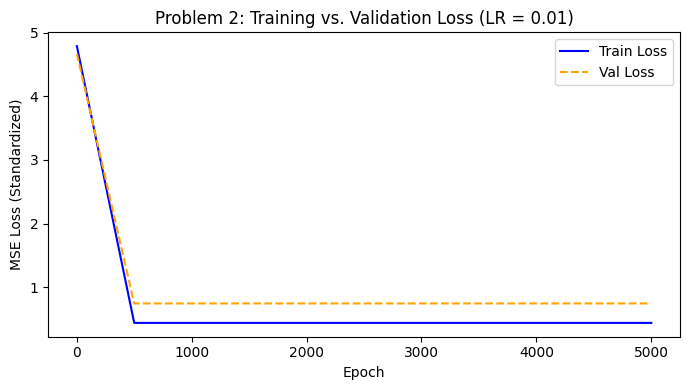

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import torch
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)

file_path = '/content/drive/My Drive/Intro to ML/Datasets/Housing.csv'
housing_df = pd.read_csv(file_path)

binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    if col in housing_df.columns and housing_df[col].dtype == object:
        housing_df[col] = housing_df[col].map({'yes': 1, 'no': 0})

if 'furnishingstatus' in housing_df.columns and housing_df['furnishingstatus'].dtype == object:
    housing_df['furnishingstatus'] = housing_df['furnishingstatus'].map({
        'unfurnished': 0, 'semi-furnished': 1, 'furnished': 2
    })

def train_housing_model(X_data, y_data, learning_rates, epochs=5000):
    X_train, X_val, y_train, y_val = train_test_split(
        X_data, y_data, test_size=0.20, random_state=42
    )
    scaler_X, scaler_y = StandardScaler(), StandardScaler()

    X_train_s = torch.tensor(scaler_X.fit_transform(X_train), dtype=torch.float32)
    X_val_s = torch.tensor(scaler_X.transform(X_val), dtype=torch.float32)
    y_train_s = torch.tensor(scaler_y.fit_transform(y_train.reshape(-1, 1)), dtype=torch.float32)
    y_val_s = torch.tensor(scaler_y.transform(y_val.reshape(-1, 1)), dtype=torch.float32)

    num_features = X_train_s.shape[1]
    all_results = {}

    for lr in learning_rates:
        weights = torch.randn(num_features, 1, requires_grad=True)
        bias = torch.zeros(1, requires_grad=True)
        optimizer = optim.SGD([weights, bias], lr=lr)

        logs = []
        for epoch in range(1, epochs + 1):
            y_pred_train = X_train_s @ weights + bias
            train_loss = torch.mean((y_pred_train - y_train_s) ** 2)

            optimizer.zero_grad()
            train_loss.backward()
            optimizer.step()

            with torch.no_grad():
                y_pred_val = X_val_s @ weights + bias
                val_loss = torch.mean((y_pred_val - y_val_s) ** 2)

            if epoch % 500 == 0 or epoch == 1:
                logs.append((epoch, train_loss.item(), val_loss.item()))

        all_results[lr] = (weights.detach().numpy().flatten(), bias.detach().item(), logs)

    return all_results

learning_rates_housing = [0.1, 0.01, 0.001, 0.0001]

print("\n=================== PROBLEM 2: 5 INPUT FEATURES ===================")
p2_features = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
X_p2 = housing_df[p2_features].values
y_p2 = housing_df['price'].values

p2_results = train_housing_model(X_p2, y_p2, learning_rates_housing)

for lr, (w, b, logs) in p2_results.items():
    print(f"\n--- LR: {lr} ---")
    print(f"{'Epoch':<6} | {'Train Loss':<10} | {'Val Loss':<10}")
    print("-" * 32)
    for epoch, tr_l, val_l in logs:
        print(f"{epoch:<6d} | {tr_l:<10.4f} | {val_l:<10.4f}")
    print("Params:", [round(float(x), 4) for x in w], f"bias: {b:.4f}")

plt.figure(figsize=(7, 4))
best_p2_logs = p2_results[0.01][2]
epochs_p2 = [item[0] for item in best_p2_logs]
train_p2 = [item[1] for item in best_p2_logs]
val_p2 = [item[2] for item in best_p2_logs]

plt.plot(epochs_p2, train_p2, label='Train Loss', color='blue')
plt.plot(epochs_p2, val_p2, label='Val Loss', color='orange', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss (Standardized)')
plt.title('Problem 2: Training vs. Validation Loss (LR = 0.01)')
plt.legend()
plt.tight_layout()
plt.show()
plt.close()


=================== PROBLEM 3: ALL INPUT FEATURES ===================

--- LR: 0.1 ---
Epoch  | Train Loss | Val Loss  
--------------------------------
1      | 3.8049     | 2.0558    
500    | 0.3146     | 0.5746    
1000   | 0.3146     | 0.5746    
1500   | 0.3146     | 0.5746    
2000   | 0.3146     | 0.5746    
2500   | 0.3146     | 0.5746    
3000   | 0.3146     | 0.5746    
3500   | 0.3146     | 0.5746    
4000   | 0.3146     | 0.5746    
4500   | 0.3146     | 0.5746    
5000   | 0.3146     | 0.5746    
Params: [0.2957, 0.0334, 0.2979, 0.1983, 0.073, 0.0509, 0.1073, 0.0857, 0.2064, 0.1098, 0.1519, 0.0901] bias: 0.0000

--- LR: 0.01 ---
Epoch  | Train Loss | Val Loss  
--------------------------------
1      | 5.1779     | 7.7257    
500    | 0.3148     | 0.5742    
1000   | 0.3146     | 0.5746    
1500   | 0.3146     | 0.5746    
2000   | 0.3146     | 0.5746    
2500   | 0.3146     | 0.5746    
3000   | 0.3146     | 0.5746    
3500   | 0.3146     | 0.5746    
4000   | 0.3146   

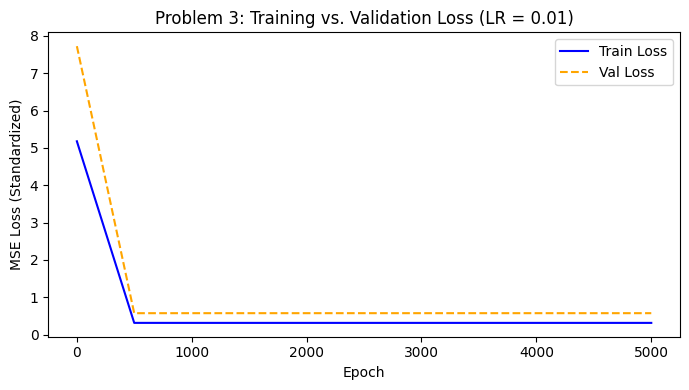

In [ ]:
print("\n=================== PROBLEM 3: ALL INPUT FEATURES ===================")
p3_features = [c for c in housing_df.columns if c != 'price']
X_p3 = housing_df[p3_features].values
y_p3 = housing_df['price'].values

p3_results = train_housing_model(X_p3, y_p3, learning_rates_housing)

for lr, (w, b, logs) in p3_results.items():
    print(f"\n--- LR: {lr} ---")
    print(f"{'Epoch':<6} | {'Train Loss':<10} | {'Val Loss':<10}")
    print("-" * 32)
    for epoch, tr_l, val_l in logs:
        print(f"{epoch:<6d} | {tr_l:<10.4f} | {val_l:<10.4f}")
    print("Params:", [round(float(x), 4) for x in w], f"bias: {b:.4f}")

plt.figure(figsize=(7, 4))
best_p3_logs = p3_results[0.01][2]
epochs_p3 = [item[0] for item in best_p3_logs]
train_p3 = [item[1] for item in best_p3_logs]
val_p3 = [item[2] for item in best_p3_logs]

plt.plot(epochs_p3, train_p3, label='Train Loss', color='blue')
plt.plot(epochs_p3, val_p3, label='Val Loss', color='orange', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss (Standardized)')
plt.title('Problem 3: Training vs. Validation Loss (LR = 0.01)')
plt.legend()
plt.tight_layout()
plt.show()
plt.close()